# Similarity structure of the recordings and the fitted models (Fig. 12)

Reproduces Fig. 12 and the numbers of the App. K paragraph on similarity structure from the
saved fits of `fit_grid_cells` and `fit_place_cells`. Nothing is refitted.

The fitted generators are skew-symmetric and commute, so the cosine similarity between the
population vectors at two positions depends on their displacement alone (Eq. 3),

$$C(\Delta x, \Delta y) = \frac{\mathbf{p}_0^\top e^{\Delta x G_x + \Delta y G_y}\mathbf{p}_0}{\lVert\mathbf{p}_0\rVert^2}.$$

The recordings need not satisfy this. The notebook compares the two in four ways.

1. The recorded similarity averaged over all pairs of bins with the same displacement, against
   the fitted similarity function (panels a, d).
2. The recorded similarity of individual pairs of bins, against the model and against the
   recorded displacement average itself (b, e).
3. The fitted wavevectors, each weighted by its share of Eq. 4 (c, f).
4. The recorded similarity map from every reference bin, correlated with the model's and with
   the displacement average (g).

Similarity is the cosine similarity throughout. The recorded rates are not equinorm, so the
normalization matters for the data. For the model it is the constant
$\lVert\mathbf{p}_0\rVert^2$.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import expm

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures" / "similarity"
FITS = {
    "grid": REPO_ROOT / "data" / "gc_fit_commuting.npz",
    "place": REPO_ROOT / "data" / "ca1_fit_one_animal_si0.50.npz",
}

MAX_LAG = 16  # largest displacement per axis in bins entering the scores, half the arena side
N_CHECK = 200  # displacements at which Eq. 3 is evaluated from the saved generators
WEIGHT_SHOWN = 0.01  # wavevector pairs with a larger share of the similarity are listed
SEED = 0

# The rates are non-negative, so the recorded similarity never crosses zero. A sequential map
# over the occupied range shows its structure.
CMAP = "magma"

# Fig. 12 is drawn at printed size, one svg per panel, with the rows assembled in Inkscape.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "stix",
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.linewidth": 0.6,
})
MAP_SIZE = 1.05  # inches, each kernel panel
CUT_SIZE = (1.6, 1.25)
WAVEVECTOR_SIZE = (1.25, 1.25)
AGREEMENT_SIZE = 1.1  # inches, each panel of g without its color bar
WAVEVECTOR_RANGE = 4.2  # cycles per arena side shown per axis

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["figure.dpi"] = 150
FIGURE_DIR.mkdir(exist_ok=True)


def save_print(fig, stem):
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight", pad_inches=0.02)

## Similarity and its displacement average

`C[i, j, k, l]` is the cosine similarity between the population vectors at bins $(i, j)$ and
$(k, l)$. Its displacement average is the mean of `C` over all pairs with the same displacement.
A translation-invariant similarity equals its displacement average. Agreement between the
recorded similarity and a prediction of it is scored over pairs of bins by the correlation and
by the fraction of variance explained, $1 - \langle (C - \hat C)^2\rangle / \mathrm{var}(C)$,
which also penalizes an offset.

In [2]:
def cosine_similarity(maps):
    """Cosine similarity between the population vectors at every pair of bins, `maps` indexed (unit, bins_x, bins_y)."""
    n = maps.shape[1]
    p = maps.reshape(len(maps), -1).T.astype(np.float64)
    p /= np.linalg.norm(p, axis=1, keepdims=True)
    return (p @ p.T).reshape(n, n, n, n)


def displacement_average(C):
    """Mean of `C` over all pairs with the same displacement, indexed `[dx + n - 1, dy + n - 1]`."""
    n = C.shape[0]
    total, count = np.zeros((2 * n - 1, 2 * n - 1)), np.zeros((2 * n - 1, 2 * n - 1))
    for i in range(n):
        for j in range(n):
            window = (slice(n - 1 - i, 2 * n - 1 - i), slice(n - 1 - j, 2 * n - 1 - j))
            total[window] += C[i, j]
            count[window] += 1
    return total / count


def from_average(average, n):
    """The translation-invariant similarity with this displacement average."""
    C = np.empty((n, n, n, n))
    for i in range(n):
        for j in range(n):
            C[i, j] = average[n - 1 - i : 2 * n - 1 - i, n - 1 - j : 2 * n - 1 - j]
    return C


def within_lag(n, max_lag):
    """Pairs of bins at most `max_lag` apart per axis, a bin paired with itself excluded."""
    lag = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    near = (lag <= max_lag)[:, None, :, None] & (lag <= max_lag)[None, :, None, :]
    return near & ~((lag == 0)[:, None, :, None] & (lag == 0)[None, :, None, :])


def agreement(C, prediction, pairs):
    """Correlation and fraction of variance of `C` explained by `prediction` over `pairs`."""
    c, q = C[pairs], prediction[pairs]
    return np.corrcoef(c, q)[0, 1], 1 - ((c - q) ** 2).mean() / c.var()


def cut_along_x(C, lags):
    """10th, 50th and 90th percentile of `C` over all pairs displaced by (dx, 0), per dx in `lags`."""
    n = C.shape[0]
    Cx = np.diagonal(C, axis1=1, axis2=3)  # [i, k, j]: bin (i, j) against bin (k, j)
    out = []
    for dx in lags:
        i = np.arange(max(0, -dx), min(n, n - dx))
        out.append(np.percentile(Cx[i, i + dx], [10, 50, 90]))
    return np.array(out).T


def per_reference_correlation(C, prediction, pairs):
    """Correlation between `C` and `prediction` over the bins paired with each reference bin, shape (n, n)."""
    n = C.shape[0]
    r = np.empty((n, n))
    for i in range(n):
        for j in range(n):
            r[i, j] = np.corrcoef(C[i, j][pairs[i, j]], prediction[i, j][pairs[i, j]])[0, 1]
    return r

## The saved fits

Per dataset: the recorded maps, the maps generated by the model fitted to the full arena, and
its generators, mixing matrix and wavevectors. From these, the two similarities and their
displacement averages.


In [3]:
def load(path):
    d = np.load(path)
    return {key: d[name].astype(np.float64) for key, name in [
        ("data", "experimental"), ("model", "generated"), ("Gx", "Gx"), ("Gy", "Gy"), ("R", "R"), ("wavevectors", "wavevectors"),
    ]}


fits = {name: load(path) for name, path in FITS.items()}
for f in fits.values():
    n = f["data"].shape[1]
    f["C_data"], f["C_model"] = cosine_similarity(f["data"]), cosine_similarity(f["model"])
    f["average_data"], f["average_model"] = displacement_average(f["C_data"]), displacement_average(f["C_model"])
    f["near"] = within_lag(n, MAX_LAG)

## Checks

The model is equinorm and translation invariant by construction. Its population norm is
constant over the arena, its similarity equals its displacement average, and that average
equals Eq. 3 evaluated from the saved generators. The recorded norm varies over the arena,
which the model cannot reproduce.


In [4]:
rng = np.random.default_rng(SEED)
for name, f in fits.items():
    n = f["data"].shape[1]
    norms = {k: np.linalg.norm(f[k].reshape(len(f[k]), -1), axis=0) for k in ("data", "model")}
    invariance_gap = np.abs(f["C_model"] - from_average(f["average_model"], n)).max()

    p0 = f["model"][:, n // 2, n // 2]
    steps = rng.integers(-(n - 1), n, size=(N_CHECK, 2))
    eq3 = np.array([p0 @ expm((2 / n) * (dx * f["Gx"] + dy * f["Gy"])) @ p0 for dx, dy in steps]) / (p0 @ p0)
    eq3_gap = np.abs(eq3 - f["average_model"][steps[:, 0] + n - 1, steps[:, 1] + n - 1]).max()
    assert invariance_gap < 1e-5 and eq3_gap < 1e-5

    print(f"{name}: ||p|| std/mean over the arena, data {norms['data'].std() / norms['data'].mean():.2f}, model {norms['model'].std() / norms['model'].mean():.0e}")
    print(f"  model similarity vs its displacement average, max |diff| {invariance_gap:.0e}; displacement average vs Eq. 3 at {N_CHECK} displacements, max |diff| {eq3_gap:.0e}")

grid: ||p|| std/mean over the arena, data 0.18, model 2e-07
  model similarity vs its displacement average, max |diff| 3e-07; displacement average vs Eq. 3 at 200 displacements, max |diff| 3e-06
place: ||p|| std/mean over the arena, data 0.21, model 3e-07
  model similarity vs its displacement average, max |diff| 8e-07; displacement average vs Eq. 3 at 200 displacements, max |diff| 3e-06


## Scores

The recorded displacement average against the fitted similarity function, over displacements
up to `MAX_LAG` per axis (panels a, d). Then the recorded similarity of individual pairs of
bins over the same displacements, against the model and against the recorded displacement
average itself (b, e).


In [5]:
for name, f in fits.items():
    n = f["data"].shape[1]
    window = slice(n - 1 - MAX_LAG, n + MAX_LAG)
    r_average = np.corrcoef(f["average_data"][window, window].ravel(), f["average_model"][window, window].ravel())[0, 1]
    print(f"{name}: recorded displacement average vs fitted similarity function, correlation {r_average:.2f}")
    for label, prediction in [("model", f["C_model"]), ("displacement average", from_average(f["average_data"], n))]:
        r, explained = agreement(f["C_data"], prediction, f["near"])
        print(f"  recorded similarity over pairs vs {label:20s}: correlation {r:.2f}, variance explained {explained:.2f}")

grid: recorded displacement average vs fitted similarity function, correlation 0.94
  recorded similarity over pairs vs model               : correlation 0.77, variance explained 0.54
  recorded similarity over pairs vs displacement average: correlation 0.81, variance explained 0.65
place: recorded displacement average vs fitted similarity function, correlation 0.98
  recorded similarity over pairs vs model               : correlation 0.88, variance explained 0.76
  recorded similarity over pairs vs displacement average: correlation 0.90, variance explained 0.81


## Fig. 12 a to f

Per dataset, one file per panel. The recorded displacement average and the fitted similarity
function on one color scale (a, d). The similarity between bins displaced by $(\Delta x, 0)$,
as the median and 10th to 90th percentile over all such pairs for the data and the single
curve of the model (b, e). The fitted wavevectors as gray dots at $\pm\boldsymbol{\lambda}_i$
in cycles per arena side, each with a black disc whose area is the block's share of the
similarity function (c, f).

That share is the weight $\alpha_{0,i}^2$ of Eq. 4 summed over the block, with
$\boldsymbol{\alpha}_0 = R\,\mathbf{p}_0 / \lVert\mathbf{p}_0\rVert$. Transport rotates each
block without changing its length, so the weights are the same at every position. Eq. 4 with
these weights is checked against the model's similarity first. For odd $N$ one direction does
not transport and adds a constant. The blocks with a share above `WEIGHT_SHOWN` are listed.


grid: 7 of 51 blocks above 1%, together 0.96; untransported direction 0.0000
  weight  cycles per arena side  orientation (deg)
   0.751                   0.05                 34
   0.064                   2.69                112
   0.039                   2.73                 47
   0.038                   2.92                170
   0.033                   0.15                 75
   0.019                   2.92                170
   0.019                   0.31                140


place: 21 of 51 blocks above 1%, together 0.90; untransported direction 0.0002
  weight  cycles per arena side  orientation (deg)
   0.225                   0.19                145
   0.105                   0.43                 64
   0.085                   0.80                101
   0.081                   1.03                137
   0.038                   0.79                  4
   0.036                   0.76                 44
   0.033                   1.73                134
   0.033                   0.83                169
   0.031                   1.20                 68
   0.030                   1.46                111
   0.028                   1.35                 89
   0.028                   1.54                157
   0.025                   1.31                 52
   0.019                   0.57                  9
   0.018                   1.41                  5
   0.017                   2.26                 84
   0.015                   1.61                 97
   

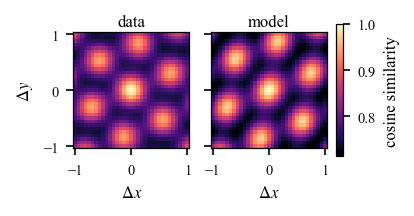

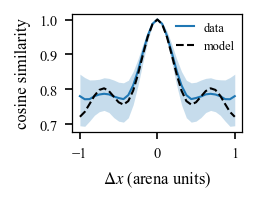

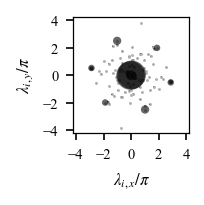

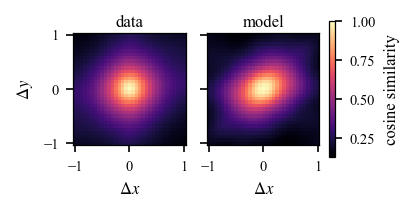

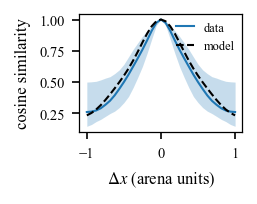

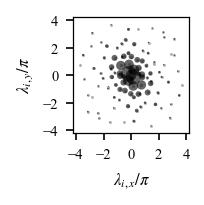

In [6]:
for name, f in fits.items():
    n = f["data"].shape[1]
    window = slice(n - 1 - MAX_LAG, n + MAX_LAG)
    extent = np.array([-1, 1, -1, 1]) * (MAX_LAG + 0.5) * 2 / n
    lags = np.arange(-MAX_LAG, MAX_LAG + 1)
    vmin = min(np.nanmin(f["average_data"][window, window]), np.nanmin(f["average_model"][window, window]))

    fig, axs = plt.subplots(1, 2, figsize=(2 * MAP_SIZE + 0.55, MAP_SIZE + 0.3), layout="constrained")
    for ax, (label, average) in zip(axs, (("data", f["average_data"]), ("model", f["average_model"]))):
        image = ax.imshow(average[window, window].T, origin="lower", cmap=CMAP, vmin=vmin, vmax=1, extent=extent)
        ax.set_title(label, fontsize=8, pad=3)
        ax.set_xlabel(r"$\Delta x$")
        ax.set_xticks([-1, 0, 1])
        ax.set_yticks([-1, 0, 1])
    axs[0].set_ylabel(r"$\Delta y$")
    axs[1].set_yticklabels([])
    fig.colorbar(image, ax=axs, shrink=0.85, pad=0.03).set_label("cosine similarity", fontsize=8)
    save_print(fig, f"app_{name}_similarity_kernels")

    fig, ax = plt.subplots(figsize=CUT_SIZE, layout="constrained")
    low, median, high = cut_along_x(f["C_data"], lags)
    ax.fill_between(lags * 2 / n, low, high, color="C0", alpha=0.25, linewidth=0)
    ax.plot(lags * 2 / n, median, color="C0", linewidth=1, label="data")
    ax.plot(lags * 2 / n, f["average_model"][lags + n - 1, n - 1], "k--", linewidth=1, label="model")
    ax.set_xlabel(r"$\Delta x$ (arena units)")
    ax.set_ylabel("cosine similarity")
    ax.set_xticks([-1, 0, 1])
    ax.legend(frameon=False, loc="upper right", handlelength=1.4, borderaxespad=0.2)
    save_print(fig, f"app_{name}_similarity_cut")

    lam, n_paired = f["wavevectors"], 2 * len(f["wavevectors"])
    p0 = f["model"][:, n // 2, n // 2]
    alpha0 = f["R"] @ p0 / np.linalg.norm(p0)
    weight = alpha0[0:n_paired:2] ** 2 + alpha0[1:n_paired:2] ** 2
    static = (alpha0[n_paired:] ** 2).sum()
    steps = np.stack(np.meshgrid(np.arange(n) - n // 2, np.arange(n) - n // 2, indexing="ij"), axis=-1)
    eq4 = np.cos((2 / n) * steps @ lam.T) @ weight + static
    assert np.abs(eq4 - f["C_model"][n // 2, n // 2]).max() < 1e-5

    both = np.concatenate([lam, -lam]) / np.pi
    fig, ax = plt.subplots(figsize=WAVEVECTOR_SIZE, layout="constrained")
    ax.scatter(both[:, 0], both[:, 1], s=2, color="0.7", linewidth=0)
    ax.scatter(both[:, 0], both[:, 1], s=250 * np.tile(weight, 2), color="k", alpha=0.6, linewidth=0)
    ax.set_aspect("equal")
    ax.set_xlim(-WAVEVECTOR_RANGE, WAVEVECTOR_RANGE)
    ax.set_ylim(-WAVEVECTOR_RANGE, WAVEVECTOR_RANGE)
    ax.set_xticks([-4, -2, 0, 2, 4])
    ax.set_yticks([-4, -2, 0, 2, 4])
    ax.set_xlabel(r"$\lambda_{i,x} / \pi$")
    ax.set_ylabel(r"$\lambda_{i,y} / \pi$")
    save_print(fig, f"app_{name}_similarity_wavevectors")

    cycles = np.hypot(lam[:, 0], lam[:, 1]) / np.pi
    orientation = np.degrees(np.arctan2(lam[:, 1], lam[:, 0])) % 180
    shown = [k for k in np.argsort(-weight) if weight[k] > WEIGHT_SHOWN]
    print(f"{name}: {len(shown)} of {len(weight)} blocks above {WEIGHT_SHOWN:.0%}, together {weight[shown].sum():.2f}; untransported direction {static:.4f}")
    print("  weight  cycles per arena side  orientation (deg)")
    for k in shown:
        print(f"  {weight[k]:6.3f}  {cycles[k]:21.2f}  {orientation[k]:17.0f}")

## Fig. 12 g

For every reference bin, the correlation between the recorded similarity map from that bin
and the model's, or the recorded displacement average, over the other bins within `MAX_LAG` per
axis. Both references are translation invariant, so the maps show how far the recorded
similarity is from that, and where.

grid vs model: median over reference bins 0.82
grid vs data average: median over reference bins 0.86
place vs model: median over reference bins 0.90
place vs data average: median over reference bins 0.92


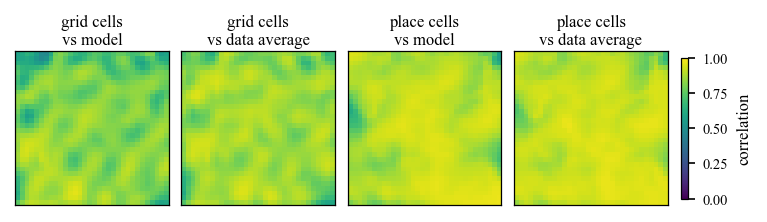

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(4 * AGREEMENT_SIZE + 0.6, AGREEMENT_SIZE + 0.3), layout="constrained")
k = 0
for name, f in fits.items():
    n = f["data"].shape[1]
    references = {"model": f["C_model"], "data average": from_average(f["average_data"], n)}
    for label, prediction in references.items():
        agreement_map = per_reference_correlation(f["C_data"], prediction, f["near"])
        image = axs[k].imshow(agreement_map.T, origin="lower", cmap="viridis", vmin=0, vmax=1)
        axs[k].set_title(f"{name} cells\nvs {label}", fontsize=8, pad=3)
        axs[k].set_xticks([])
        axs[k].set_yticks([])
        k += 1
        print(f"{name} vs {label}: median over reference bins {np.median(agreement_map):.2f}")
fig.colorbar(image, ax=axs, shrink=0.85, pad=0.02).set_label("correlation", fontsize=8)
save_print(fig, "app_similarity_agreement")